# HW2 — 01: Train a small MLP from scratch

逐步实现并训练六分类声音模型。这里的代码单元直接包含训练循环、反向传播和参数更新。

**Run all cells in order.** Use the project `.venv` kernel with `requirements-notebook.txt` installed. This notebook regenerates the MLP checkpoint and evaluation artifacts. It does not call `training.train.main()`.

Data: 240 ESC-50 clips; folds 1–3 train, 4 validation, 5 test. Our MLP learns from scratch. Notebook 02 fine-tunes a pretrained audio CNN on exactly the same split.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
ROOT = next((p for p in [ROOT, *ROOT.parents]
             if (p / "training/model.py").is_file() and (p / "frontend/package.json").is_file()), ROOT)
assert (ROOT / "training").exists(), "Open this notebook from the sound-detective repository."
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Repository:", ROOT.name)

Repository: sound-detective


In [2]:
"""Reproduce selection on validation only, then evaluate the held-out test fold."""
import copy
import json
import random
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler
from training.features import CLASSES, LABELS, FEATURE_VERSION, INPUT_DIM, extract_features
"""A small feed-forward network; outputs logits (not probabilities)."""
from torch import nn
from training.features import INPUT_DIM

class SoundMLP(nn.Module):
    def __init__(self, hidden=64, dropout=0.2):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(INPUT_DIM, hidden), nn.ReLU(),
                                    nn.Dropout(dropout), nn.Linear(hidden, 6))

    def forward(self, x):
        return self.layers(x)


ROOT = Path.cwd()
OUT = ROOT / 'training/results'
MODEL_DIR = ROOT / 'backend/model'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / 'data/cache').mkdir(parents=True, exist_ok=True)
SEED = 7400

def scores(y, predictions):
    return {'accuracy': float(accuracy_score(y, predictions)),
            'macro_f1': float(f1_score(y, predictions, labels=range(6), average='macro', zero_division=0)),
            'confusion_matrix': confusion_matrix(y, predictions, labels=range(6)).tolist()}

## 1. Prepare data
Download only the selected classes. 同源录音不能跨训练、验证、测试集。

In [3]:
# Download the 240 selected recordings only if they are not already present.
from training.prepare import main as prepare_data
if not (ROOT / 'data/raw/manifest.json').exists():
    prepare_data()

## 2. Features and split
64 log-mel + 20 MFCC means/stds = 168 features. Scaling is fitted on training data only. The imported extractor is the same one used by the web API.

In [4]:
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
rows = json.loads((ROOT / 'data/raw/manifest.json').read_text())
cache = ROOT / 'data/cache/features.npz'
filenames = [r['filename'] for r in rows]
if cache.exists():
    saved = np.load(cache)
    assert saved['version'].item() == FEATURE_VERSION and saved['filenames'].tolist() == filenames
    X = saved['X']
else:
    X = np.stack([extract_features(*sf.read(ROOT / 'data/raw/audio' / r['filename'])) for r in rows])
    np.savez(cache, X=X, filenames=filenames, version=FEATURE_VERSION)
y = np.array([CLASSES.index(r['category']) for r in rows])
fold = np.array([int(r['fold']) for r in rows])
masks = {'train': fold <= 3, 'validation': fold == 4, 'test': fold == 5}
sources = {name: {r['src_file'] for r, keep in zip(rows, mask) if keep} for name, mask in masks.items()}
assert not (sources['train'] & sources['validation'] or sources['train'] & sources['test'] or sources['validation'] & sources['test'])
scaler = StandardScaler().fit(X[masks['train']])
xs = {name: torch.tensor(scaler.transform(X[mask]), dtype=torch.float32) for name, mask in masks.items()}
ys = {name: torch.tensor(y[mask], dtype=torch.long) for name, mask in masks.items()}
loss_fn = torch.nn.CrossEntropyLoss()
trials, selected = [], None
# A small, declared search; test results never enter selection.

## 3. Train the MLP
One hidden layer; cross-entropy loss; SGD with momentum. `backward()` computes gradients, then `step()` updates parameters. The declared 12-run search and early stopping use validation loss, never test performance.

In [5]:
for hidden in [32, 64, 128]:
    for lr in [0.01, 0.03]:
        for dropout in [0.2, 0.5]:
            random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
            model = SoundMLP(hidden, dropout)
            optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0.001)
            history, best, best_loss, stale = [], None, float('inf'), 0
            for epoch in range(1, 301):
                model.train()
                for indices in torch.randperm(len(xs['train'])).split(24):
                    optimizer.zero_grad()  # Clear gradients from the previous batch.
                    logits = model(xs['train'][indices])  # Forward propagation.
                    loss = loss_fn(logits, ys['train'][indices])
                    loss.backward()  # Autograd applies the chain rule.
                    optimizer.step()  # Gradient descent with momentum.
                model.eval()
                with torch.no_grad():
                    entry = {'epoch': epoch}
                    for name in ['train', 'validation']:
                        logits = model(xs[name])
                        entry[f'{name}_loss'] = float(loss_fn(logits, ys[name]))
                        entry[f'{name}_accuracy'] = float((logits.argmax(1) == ys[name]).float().mean())
                history.append(entry)
                if entry['validation_loss'] < best_loss - 1e-6:
                    best_loss = entry['validation_loss']; stale = 0
                    best = {'state': copy.deepcopy(model.state_dict()), 'epoch': epoch}
                else:
                    stale += 1
                if stale >= 45:
                    break
            config = {'hidden': hidden, 'dropout': dropout, 'learning_rate': lr}
            trials.append({**config, 'best_epoch': best['epoch'], 'validation_loss': best_loss})
            print(trials[-1], flush=True)
            if selected is None or best_loss < selected['validation_loss']:
                selected = {**best, **config, 'validation_loss': best_loss, 'history': history}

{'hidden': 32, 'dropout': 0.2, 'learning_rate': 0.01, 'best_epoch': 29, 'validation_loss': 0.5357276797294617}


{'hidden': 32, 'dropout': 0.5, 'learning_rate': 0.01, 'best_epoch': 35, 'validation_loss': 0.4663059711456299}


{'hidden': 32, 'dropout': 0.2, 'learning_rate': 0.03, 'best_epoch': 19, 'validation_loss': 0.5020487904548645}


{'hidden': 32, 'dropout': 0.5, 'learning_rate': 0.03, 'best_epoch': 27, 'validation_loss': 0.48206281661987305}


{'hidden': 64, 'dropout': 0.2, 'learning_rate': 0.01, 'best_epoch': 38, 'validation_loss': 0.4166005551815033}


...

{'hidden': 64, 'dropout': 0.5, 'learning_rate': 0.03, 'best_epoch': 8, 'validation_loss': 0.41196978092193604}


{'hidden': 128, 'dropout': 0.2, 'learning_rate': 0.01, 'best_epoch': 32, 'validation_loss': 0.43504300713539124}


{'hidden': 128, 'dropout': 0.5, 'learning_rate': 0.01, 'best_epoch': 44, 'validation_loss': 0.44182825088500977}


{'hidden': 128, 'dropout': 0.2, 'learning_rate': 0.03, 'best_epoch': 8, 'validation_loss': 0.4594214856624603}


{'hidden': 128, 'dropout': 0.5, 'learning_rate': 0.03, 'best_epoch': 12, 'validation_loss': 0.4952026903629303}


## 4. Shallow baseline
Logistic regression receives the identical standardized features and split. Choose regularization using validation accuracy.

In [6]:
baseline_trials, baseline = [], None
for c in [0.01, 0.1, 1, 10, 100]:
    candidate = LogisticRegression(C=c, max_iter=3000, random_state=SEED).fit(xs['train'].numpy(), ys['train'].numpy())
    acc = accuracy_score(ys['validation'], candidate.predict(xs['validation'].numpy()))
    baseline_trials.append({'C': c, 'validation_accuracy': float(acc)})
    if baseline is None or acc > baseline[0]:
        baseline = (acc, candidate, c)

## 5. Final evaluation
Restore the validation-selected checkpoint and evaluate the set-aside test fold. This test set has been reported previously; it is a fixed homework comparison, not a new blind benchmark. Do not iterate based on its scores.

In [7]:
model = SoundMLP(selected['hidden'], selected['dropout'])
model.load_state_dict(selected['state']); model.eval()
report = {'seed': SEED, 'classes': CLASSES, 'labels': LABELS,
          'feature_version': FEATURE_VERSION, 'input_dim': INPUT_DIM,
          'architecture': f'{INPUT_DIM} → {selected["hidden"]} ReLU → 6',
          'config': {k: selected[k] for k in ['hidden', 'dropout', 'learning_rate', 'epoch']},
          'optimizer': 'SGD, momentum=0.9, weight_decay=0.001, batch_size=24',
          'split': {'train': 'folds 1–3', 'validation': 'fold 4', 'test': 'fold 5'},
          'counts': {name: int(mask.sum()) for name, mask in masks.items()},
          'selection': 'Minimum validation cross-entropy; early stopping patience 45; max 300 epochs. Test fold excluded from selection.',
          'trials': trials, 'baseline_trials': baseline_trials, 'baseline_C': baseline[2],
          'history': selected['history'], 'mlp': {}, 'baseline': {}, 'test_predictions': []}
with torch.no_grad():
    for name in masks:
        logits = model(xs[name])
        report['mlp'][name] = {**scores(ys[name], logits.argmax(1)), 'loss': float(loss_fn(logits, ys[name]))}
        report['baseline'][name] = scores(ys[name], baseline[1].predict(xs[name].numpy()))
    probabilities = model(xs['test']).softmax(1).numpy()
for row, probs in zip([r for r in rows if int(r['fold']) == 5], probabilities):
    report['test_predictions'].append({'filename': row['filename'], 'actual': row['category'],
                                       'predicted': CLASSES[int(probs.argmax())], 'probabilities': probs.tolist()})
report['beats_baseline'] = report['mlp']['test']['accuracy'] > report['baseline']['test']['accuracy']

## 6. Save weights and curves
The frontend and backend load these same saved artifacts. Restart the backend after retraining.

In [8]:
torch.save({'state_dict': selected['state'], 'hidden': selected['hidden'], 'dropout': selected['dropout'],
            'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist(), 'classes': CLASSES,
            'feature_version': FEATURE_VERSION}, MODEL_DIR / 'sound-mlp.pt')
(OUT / 'metrics.json').write_text(json.dumps(report, indent=2) + '\n')
np.savez(MODEL_DIR / 'baseline.npz', coef=baseline[1].coef_, intercept=baseline[1].intercept_,
         mean=scaler.mean_, scale=scaler.scale_, classes=np.array(CLASSES), C=baseline[2])
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
history = report['history']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ['train', 'validation']:
    axes[0].plot([h['epoch'] for h in history], [h[f'{name}_loss'] for h in history], label=name)
    axes[1].plot([h['epoch'] for h in history], [h[f'{name}_accuracy'] for h in history], label=name)
for ax in axes:
    ax.axvline(selected['epoch'], color='gray', ls='--', label='selected epoch'); ax.set_xlabel('Epoch'); ax.legend()
axes[0].set_ylabel('Cross-entropy loss'); axes[1].set_ylabel('Accuracy'); axes[1].set_ylim(0, 1.05)
fig.tight_layout(); fig.savefig(OUT / 'learning-curves.png', dpi=160); plt.close(fig)
print(json.dumps({'mlp_test': report['mlp']['test'], 'baseline_test': report['baseline']['test'], 'beats_baseline': report['beats_baseline']}, indent=2))

{
  "mlp_test": {
    "accuracy": 0.8541666666666666,
    "macro_f1": 0.8583333333333334,
    "confusion_matrix": [
      [
        6,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        8,
        0,
        0,
        0,
        0
      ],
      [
        0,
        0,
        7,
        1,
        0,
        0
      ],
      [
        0,
        0,
        0,
        7,
        1,
        0
      ],
      [
        1,
        0,
        0,
        0,
        6,
        1
      ],
      [
        0,
        0,
        0,
        0,
        1,
        7
      ]
    ],
    "loss": 0.7046279907226562
  },
  "baseline_test": {
    "accuracy": 0.75,
    "macro_f1": 0.750930115635998,
    "confusion_matrix": [
      [
        7,
        0,
        0,
        0,
        1,
        0
      ],
      [
        0,
        8,
        0,
        0,
        0,
        0
      ],
      [
        0,
        1,
        7,
        0,
        0,
        0
      ],


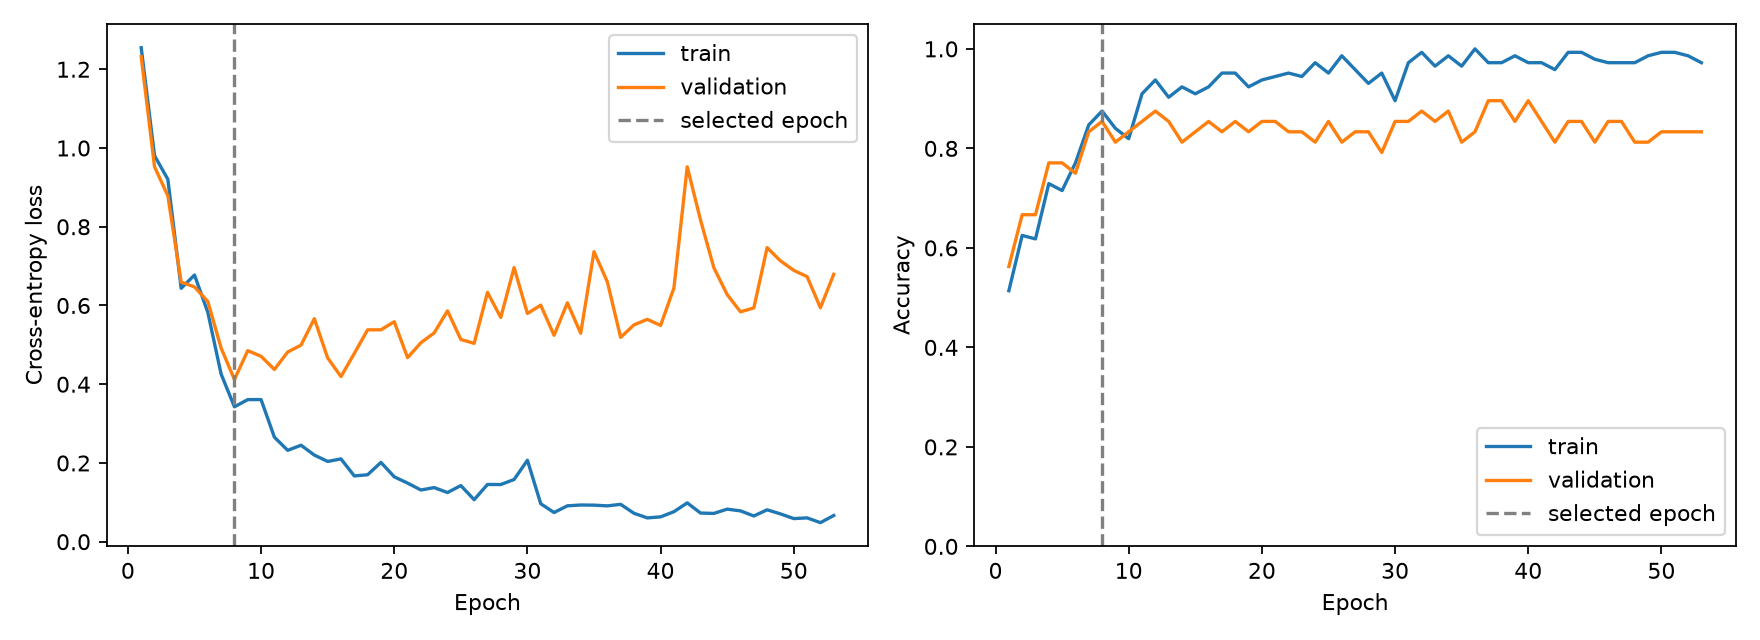

Selected configuration: {'hidden': 64, 'dropout': 0.5, 'learning_rate': 0.03, 'epoch': 8}


In [9]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'learning-curves.png')))
print('Selected configuration:', report['config'])